# IEEE 37-bus modified random sequential DDPG switching-cost beta matrix

## Purpose

The `band` reward stays fixed at `abs` alpha `0.1`; the cells differ only in beta.
The saved beta `1e-5` cell is the benchmark row.
Each cell's combined cost uses its own beta and is not comparable across cells.
Results describe this saved validation split and synthetic days only.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().parents[1]
if not (ROOT / "src/feeder").is_dir():
    raise RuntimeError("Start the kernel in the notebook directory (experiments/<feeder>/).")
sys.path.insert(0, str(ROOT / "src"))

from common.beta_matrix import (
    run_beta_matrix,
    show_beta_matrix,
    show_beta_matrix_conclusions,
    show_beta_matrix_training,
)

print("Repository root resolved.")

Repository root resolved.


## Parameters

Edit this cell, then restart the kernel and run all cells.
`MODE` selects training, evaluation, or viewing saved results.
Make sure `OVERWRITE` stays false when viewing saved results.

In [2]:
FEEDER = "ieee37mod"  # Named feeder.
DATASET = "ieee37mod-random"  # Named dataset.
SEEDS = [0, 1, 2]  # Independent training seeds.
MODE = "view"  # Read saved results.
OVERWRITE = False  # Protect existing outputs.
TRAINING_DAYS = 1000  # Complete training days per run.
SPLIT = "validation"  # Evaluation split.
EVALUATION_DAYS = None  # Evaluate the complete split.
DEVIATION = "abs"  # Absolute voltage deviation.
ALPHA = 0.1  # Deviation weight in the reward.
RATE = 20.0  # Recorded deviation rate.
BENCHMARK_BETA = 1e-5  # Saved benchmark cell.
CELLS = [  # Switching-cost beta, run name before _seed<seed>.
    (1e-3, "band_b0.001_abs_a0.1"),
    (1e-5, "band_b1e-05_abs_a0.1"),
    (1e-7, "band_b1e-07_abs_a0.1"),
]
PLOT_DAY = 0  # Selected evaluated day by zero-based position.

**Units and interfaces.** Alpha weights mean absolute voltage deviation from 1 p.u.; beta weights executed tap steps.
Physical voltage metrics share their definitions across cells.
Each cell's combined cost uses its own beta.
Do not rank cells by combined cost.

In [3]:
BASE = {
    "protocol": "sequential",
    "algorithm": "ddpg",
    "feeder": FEEDER,
    "dataset": DATASET,
    "seeds": SEEDS,
    "mode": MODE,
    "overwrite": OVERWRITE,
    "training_days": TRAINING_DAYS,
    "reward": "band",
    "deviation": DEVIATION,
    "alpha": ALPHA,
    "rate": RATE,
    "split": SPLIT,
    "evaluation_days": EVALUATION_DAYS,
    "plot_day": PLOT_DAY,
    "show_hourly_details": False,
    "root": ROOT,
}
cells = run_beta_matrix(BASE, CELLS)

Cell band_b0.001_abs_a0.1: reward band {'beta': 0.001, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}; runs results/ieee37mod-random/seq_ddpg/band_b0.001_abs_a0.1_seed0/, results/ieee37mod-random/seq_ddpg/band_b0.001_abs_a0.1_seed1/, results/ieee37mod-random/seq_ddpg/band_b0.001_abs_a0.1_seed2/
Preflight passed. No subprocess has started before this point.
Using existing saved results. View mode launches no subprocess.
Day and hour alignment passed for 200 days, 4800 hours, and 5 methods.
Cell band_b1e-05_abs_a0.1: reward band {'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}; runs results/ieee37mod-random/seq_ddpg/band_b1e-05_abs_a0.1_seed0/, results/ieee37mod-random/seq_ddpg/band_b1e-05_abs_a0.1_seed1/, results/ieee37mod-random/seq_ddpg/band_b1e-05_abs_a0.1_seed2/
Preflight passed. No subprocess has started before this point.
Using existing saved result

Day and hour alignment passed for 200 days, 4800 hours, and 5 methods.


Cell band_b1e-07_abs_a0.1: reward band {'beta': 1e-07, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}; runs results/ieee37mod-random/seq_ddpg/band_b1e-07_abs_a0.1_seed0/, results/ieee37mod-random/seq_ddpg/band_b1e-07_abs_a0.1_seed1/, results/ieee37mod-random/seq_ddpg/band_b1e-07_abs_a0.1_seed2/
Preflight passed. No subprocess has started before this point.
Using existing saved results. View mode launches no subprocess.
Day and hour alignment passed for 200 days, 4800 hours, and 5 methods.
Beta matrix identity passed: dataset, split, protocol, algorithm, seeds, and days match.


## Training records

These records cover all three beta cells, including the saved beta `1e-5` benchmark.
Each curve averages the selected seeds before smoothing.
The panels show training voltage cost and tap steps per day.

Cost includes exploration and does not represent held-out performance or prove convergence.

Run,Reward,Reward parameters,Benchmark beta,Layer sizes,Completed training days,Update counts
DDPG seed 0,band,"{'beta': 0.001, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",0.001,"[400, 300]",1000,unavailable
DDPG seed 1,band,"{'beta': 0.001, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",0.001,"[400, 300]",1000,unavailable
DDPG seed 2,band,"{'beta': 0.001, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",0.001,"[400, 300]",1000,unavailable


Run,Reward,Reward parameters,Benchmark beta,Layer sizes,Completed training days,Update counts
DDPG seed 0,band,"{'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",1e-05,"[400, 300]",1000,unavailable
DDPG seed 1,band,"{'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",1e-05,"[400, 300]",1000,unavailable
DDPG seed 2,band,"{'beta': 1e-05, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",1e-05,"[400, 300]",1000,unavailable


Run,Reward,Reward parameters,Benchmark beta,Layer sizes,Completed training days,Update counts
DDPG seed 0,band,"{'beta': 1e-07, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",1e-07,"[400, 300]",1000,unavailable
DDPG seed 1,band,"{'beta': 1e-07, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",1e-07,"[400, 300]",1000,unavailable
DDPG seed 2,band,"{'beta': 1e-07, 'deviation': 'abs', 'alpha': 0.1, 'rate': 20.0, 'voltage_min': 0.95, 'voltage_max': 1.05, 'scale': 1000.0}",1e-07,"[400, 300]",1000,unavailable


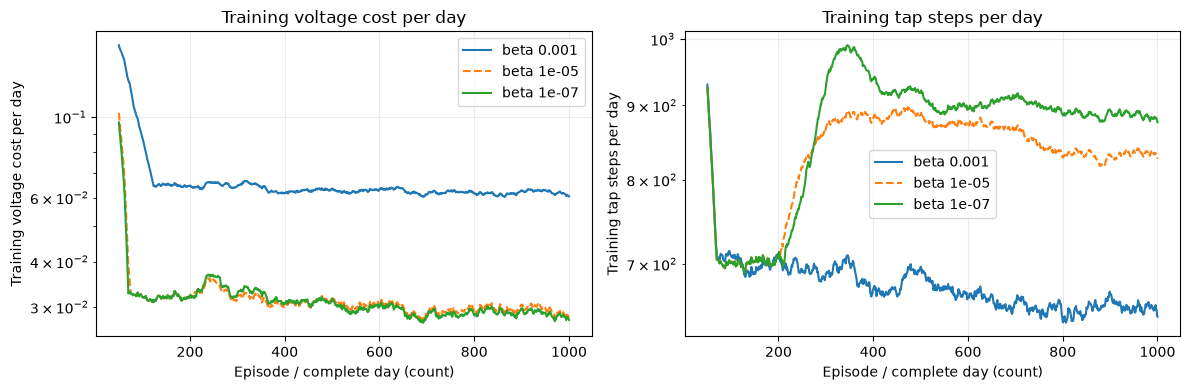

Cost uses the fixed evaluation metric on training episodes and includes exploration. It is not held-out performance or proof of convergence.

In [4]:
show_beta_matrix_training(cells);

## Switching-cost beta matrix

Each row reports the seed mean ± sample standard deviation of per-run metrics.
Paired differences match seeds and inputs; spread across three seeds is not a confidence interval.
Combined cost uses each cell's own beta and is not comparable across cells.
Feasible hours require every live node inside [0.95, 1.05] p.u.

The trade-off figure shows individual runs and cell seed means.
The distributions pool all evaluated days across seeds.

Cell,Mean daily voltage cost
beta 0.001,4.13981e-02 ± 0.00000e+00
beta 1e-05,3.64439e-03 ± 2.25802e-05
beta 1e-07,3.71608e-03 ± 3.66521e-05


Cell,Mean absolute deviation (p.u.)
beta 0.001,5.6308e-02 ± 0.0000e+00
beta 1e-05,2.9357e-02 ± 4.1534e-04
beta 1e-07,2.8720e-02 ± 5.2249e-04


Cell,Mean tap steps/day
beta 0.001,80.000 ± 0.000
beta 1e-05,454.315 ± 69.211
beta 1e-07,519.230 ± 13.371


Cell,Feasible hours (%)
beta 0.001,0.0 ± 0.0
beta 1e-05,9.7 ± 0.8
beta 1e-07,9.1 ± 1.4


Cell,Mean daily combined cost,Mean daily switching cost
beta 0.001,1.21398e-01 ± 0.00000e+00,8.00000e-02 ± 0.00000e+00
beta 1e-05,8.18754e-03 ± 7.13237e-04,4.54315e-03 ± 6.92115e-04
beta 1e-07,3.76800e-03 ± 3.54507e-05,5.19230e-05 ± 1.33710e-06


Cell,Mean daily voltage cost
beta 0.001,3.77537e-02 ± 2.25802e-05
beta 1e-07,7.16859e-05 ± 5.07486e-05


Cell,Mean absolute deviation (p.u.)
beta 0.001,2.6951e-02 ± 4.1534e-04
beta 1e-07,-6.3694e-04 ± 2.1619e-04


Cell,Mean tap steps/day
beta 0.001,-374.315 ± 69.211
beta 1e-07,64.915 ± 56.604


Selected day: validation-0000


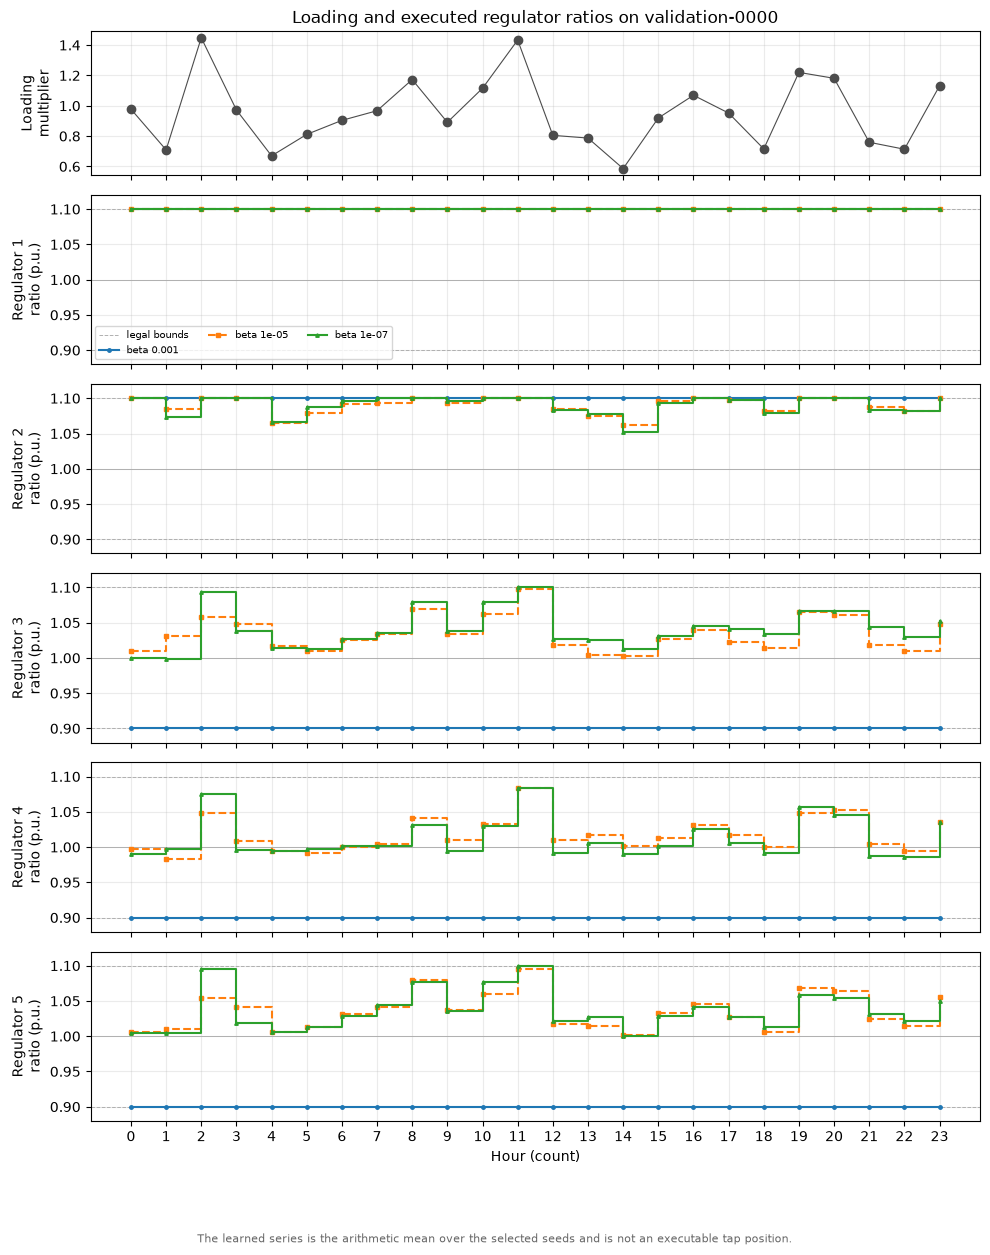

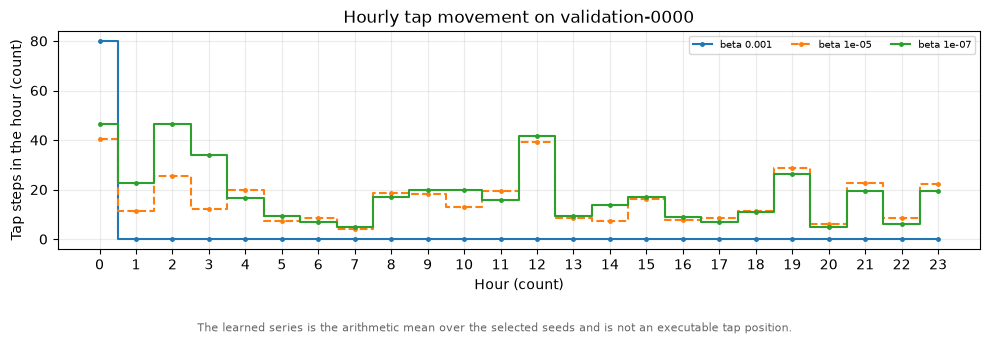

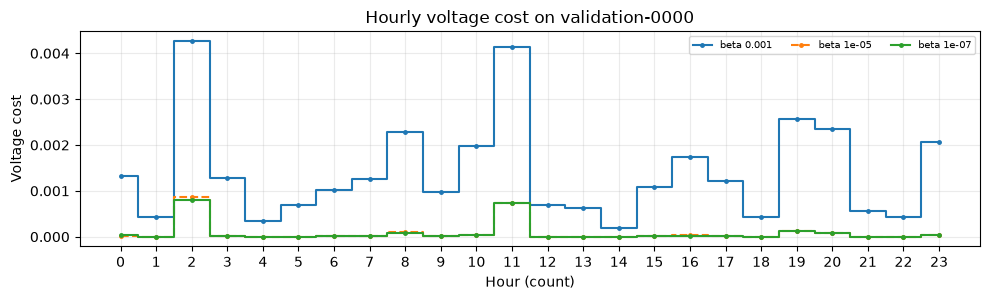

The learned series is the arithmetic mean over the selected seeds and is not an executable tap position.

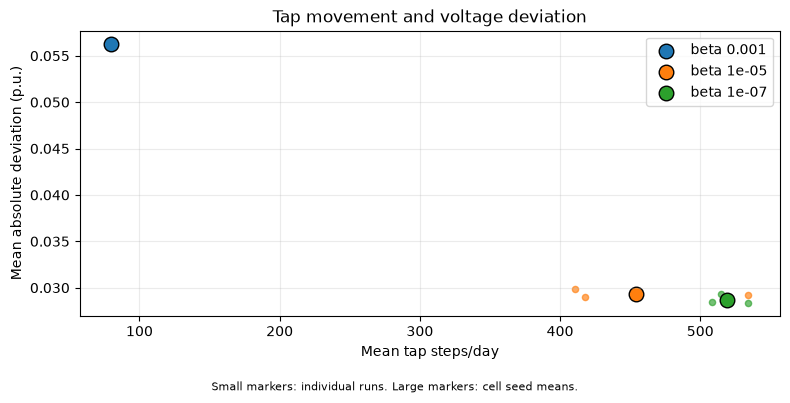

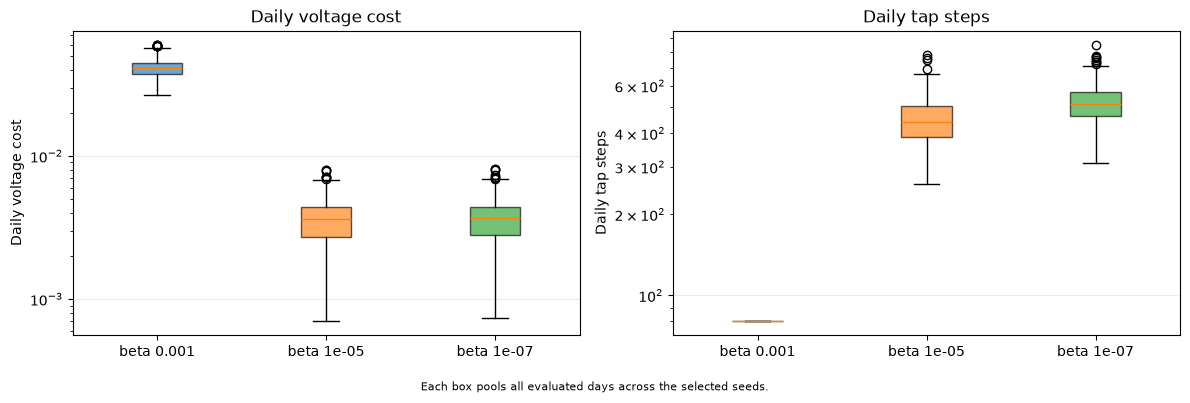

In [5]:
show_beta_matrix(cells, BENCHMARK_BETA);

## Final answers

In [6]:
show_beta_matrix_conclusions(cells, BENCHMARK_BETA)

Mean daily voltage cost: the beta 1e-05 benchmark cell has seed mean 3.64439e-03; the lowest seed mean is 3.64439e-03 for beta 1e-05.

Mean absolute deviation (p.u.): the beta 1e-05 benchmark cell has seed mean 2.9357e-02; the lowest seed mean is 2.8720e-02 for beta 1e-07.

Mean tap steps/day: the beta 1e-05 benchmark cell has seed mean 454.315; the lowest seed mean is 80.000 for beta 0.001.

Feasible hours (%): the beta 1e-05 benchmark cell has seed mean 9.7; the highest seed mean is 9.7 for beta 1e-05.

Mean tap steps/day: seed means strictly decrease as beta increases: yes. This holds on every seed individually: yes.

Mean absolute deviation (p.u.): seed means strictly increase as beta increases: yes. This holds on every seed individually: yes.

These statements describe the saved validation split and these dataset inputs only.